# Project Scope: Biodiversity in National Parks
1. **Goals:** Define concrete, measurable questions for the National Park Service:
   * What is the distribution of conservation statuses across observed species?
   * Which taxonomic categories (e.g., mammals, birds, vascular plants) face the highest likelihood of endangerment or species of concern designation?
   * Are the differences in conservation status across species categories statisically significant?
   * Which national parks record the hgihest frequency of sightings for species needing active protection?

2. **Actions & Interventions:** Identify what park management actions this analysis informs:
    * Guide resource allocation and funding for field conservation efforts toward taxonomic groups most at risk.
    * Inform targeted patrol, monitoring, and visitor awareness campagins in parks with the highest density of protected species sightings.
    * Direct future biological surveys to address gaps in sighting records or underrepresented species.

3. **Data Overview:** Map the internal data sources provided against the analytical questions:
    * `species_info.csv`: Contains taxonomic classification (`category`), scientific name (`scientific_name`), common name (`common_names`), and current federal conservatino rating (`conservation_status`).
    * `observations.csv`: Record sighting events across parks (`park_name`), linked by `scientific_name`, detailing total sightings (`observations`) over the recorded 7-day period.
    * **Granularity & Alignmnet:** Entity level links on `scientific_name` to combine conservation status with geographic observation frequency.

4. **Analytical Approach:** Outline the quantitative methods and validation steps:
    * **Description Analysis & Data Cleaning:** Audit missing values in `conservation_status` (imputing non-listed species as "No Intervention/Safe"), deduplicate records, and compute frequency distributions across categories and parks.
    * **Statistical Hypothesis Testing:** Conduct Chi-Square contigency tests (x2) to determine whether species categories (e.g., mammals vs. birds) have statistically significant differences in endangerment rates.
    * **Visualization:** Plot categorical breakdowns of protection statuses and park-specific observation counts using `seaborn` and `matplotlib`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

species = pd.read_csv('species_info.csv')
observations = pd.read_csv('observations.csv')

print("Species shape:", species.shape)
print(species.head())
print("\nObservations shape:", observations.shape)
print(observations.head())

Species shape: (5824, 4)
  category                scientific_name  \
0   Mammal  Clethrionomys gapperi gapperi   
1   Mammal                      Bos bison   
2   Mammal                     Bos taurus   
3   Mammal                     Ovis aries   
4   Mammal                 Cervus elaphus   

                                        common_names conservation_status  
0                           Gapper's Red-Backed Vole                 NaN  
1                              American Bison, Bison                 NaN  
2  Aurochs, Aurochs, Domestic Cattle (Feral), Dom...                 NaN  
3  Domestic Sheep, Mouflon, Red Sheep, Sheep (Feral)                 NaN  
4                                      Wapiti Or Elk                 NaN  

Observations shape: (23296, 3)
            scientific_name                            park_name  observations
0        Vicia benghalensis  Great Smoky Mountains National Park            68
1            Neovison vison  Great Smoky Mountains National Park

### Inspect the underlying distributions and handle the `NaN` values in `conversation_status`:

In [3]:
# 1. Inspect unique categories and federal conservation statuses
print("Unique categories:\n", species['category'].value_counts(), "\n")
print("Convservation status breakdown:\n", species['conservation_status'].value_counts(dropna=False), "\n")


# 2. Impute missing conservation statuses as 'No Intervention'
species['conservation_status'] = species['conservation_status'].fillna('No Intervention')
print("Cleaned conservation status counts:\n", species['conservation_status'].value_counts())

Unique categories:
 category
Vascular Plant       4470
Bird                  521
Nonvascular Plant     333
Mammal                214
Fish                  127
Amphibian              80
Reptile                79
Name: count, dtype: int64 

Convservation status breakdown:
 conservation_status
NaN                   5633
Species of Concern     161
Endangered              16
Threatened              10
In Recovery              4
Name: count, dtype: int64 

Cleaned conservation status counts:
 conservation_status
No Intervention       5633
Species of Concern     161
Endangered              16
Threatened              10
In Recovery              4
Name: count, dtype: int64


In [7]:
# 1. Create a boolean column for protected status
# Any status other than 'No Intervention' requires conservation action
species['is_protected'] = species['conservation_status'] != 'No Intervention'

# 2. Cross-tabulate category against protection status
category_counts = species.groupby(['category', 'is_protected']).scientific_name.nunique().reset_index()
category_pivot = category_counts.pivot(
    columns='is_protected',
    index='category',
    values='scientific_name'
).reset_index()

category_pivot.columns = ['category', 'not_protected', 'protected']

# 3. Calculate the percentage of protected species per category
category_pivot['percent_protected'] = round(
    (category_pivot['protected'] / (category_pivot['protected'] + category_pivot['not_protected'])) * 100,
    2
)

# Display sorted by highest protection percentage
category_pivot = category_pivot.sort_values(by='percent_protected', ascending=False)
category_pivot

,category,not_protected,protected,percent_protected
3,Mammal,146,30,17.05
1,Bird,413,75,15.37
0,Amphibian,72,7,8.86
2,Fish,115,11,8.73
5,Reptile,73,5,6.41
4,Nonvascular Plant,328,5,1.50
6,Vascular Plant,4216,46,1.08


### What to Look For in the Output:
* **Mammals and Birds** typically show the highest rates of protection (often around 15-17%).
* **Vascular and Nonvascular Plants** usually have much lower percetnages under federal protection (~1-2%), even though they make up the bulk of total records.

### Immediate Next Step: Statistical Signficance (x2 Test)
Determine the difference between specific groups (e.g., Mammals vs. Birds, or Mammals vs. Reptiles) is statistically significant using a Chi-Square Contingency test:

In [8]:
from scipy.stats import chi2_contingency

# Example: Mammal vs. Bird protection rates
# Replace the numbers below with the exact counts from your category_pivot output:
# [[protected_mammals, not_protected_mammals], [protected_birds, not_protected_brids]]

contingency_table = [
    [category_pivot.loc[category_pivot['category'] == 'Mammal', 'protected'].values[0],
     category_pivot.loc[category_pivot['category'] == 'Mammal', 'not_protected'].values[0]],
    [category_pivot.loc[category_pivot['category'] == 'Bird', 'protected'].values[0],
     category_pivot.loc[category_pivot['category'] == 'Bird', 'not_protected'].values[0]]
]

chi2, pval, dof, expected = chi2_contingency(contingency_table)
print(f"Chi-square p-value: {pval:.4f}")
        

Chi-square p-value: 0.6876


### Interpretation
* **Null Hypothesis:** There is no significant difference in the proportion of protected species between mammals and birds.
* **Alternative Hypothesis:** There is a significant difference in the proportion of protected species between mammals and birds.

Because p = 0.6876 > 0.05, you **faily to reject the null hypothesis.**

#### While mammals have a slightly higher observed protection rate (17.05% vs. 15.37%), this difference is not statistically significant and is likely due to random chance.

## Next Step: Test a Significant Pair
To observe a statistically significant relationship, compare **Mammals** against **Reptiles** (17.05% vs. 6.41%):

In [10]:
# Mammal vs. Reptile Chi-Square Test
contingency_mammal_reptile = [
    [category_pivot.loc[category_pivot['category'] == 'Mammal', 'protected'].values[0],
     category_pivot.loc[category_pivot['category'] == 'Mammal', 'not_protected'].values[0]],
    [category_pivot.loc[category_pivot['category'] == 'Reptile', 'protected'].values[0],
     category_pivot.loc[category_pivot['category'] == 'Reptile', 'not_protected'].values[0]]
]

chi2, pval, dof, expected = chi2_contingency(contingency_mammal_reptile)
print(f"Mammal vs. Reptile Chi-square p-value {pval:.4f}")

Mammal vs. Reptile Chi-square p-value 0.0384


### Interpretation
* **Null Hypothesis:** There is no significant difference in the proportion of protected species between mammals and reptiles.
* **Alternative Hypothesis:** There is a significant difference in the proportion of protected species between mammals and reptiles.

Because p = 0.0384 < 0.05, you **reject the null hypothesis.**

The difference in protection rates between Mammals (17.05%) and Reptiles (6.41%) is **statistically significant**. Mammals are significantly more likely to require conservation protection compared to reptiles in the observed dataset.

### **Next Steps**: Shift to investigating sightings across parks by merging `species` with `observations` to analyze which protected species are sighted most frequently:

In [13]:
# Merge protected species with park observation counts
protected_species = species[species['is_protected'] == True]
protected_obs = pd.merge(protected_species, observations, on='scientific_name')

# Total protected observations by park
park_protected_counts = protected_obs.groupby('park_name')['observations'].sum().reset_index()
print(park_protected_counts.sort_values(by='observations', ascending=False))

                             park_name  observations
2            Yellowstone National Park         44583
3               Yosemite National Park         26913
0                  Bryce National Park         18609
1  Great Smoky Mountains National Park         12816


In [15]:
# 1. Filter observations for endangered / protected species and find top sightings
top_protected_species = (
    protected_obs.groupby(['park_name', 'common_names', 'category'])['observations']
    .sum()
    .reset_index()
    .sort_values(by=['park_name', 'observations'], ascending=[True, False])
)

# 2. View the top 3 most-observed protected species in each park
top_by_park = top_protected_species.groupby('park_name').head(3)
top_by_park

,park_name,common_names,category,observations
87,Bryce National Park,"Little Brown Bat, Little Brown Myotis",Mammal,298
88,Bryce National Park,"Little Brown Bat, Little Brown Myotis, Little ...",Mammal,298
89,Bryce National Park,Little Brown Myotis,Mammal,298
277,Great Smoky Mountains National Park,"Little Brown Bat, Little Brown Myotis",Mammal,174
278,Great Smoky Mountains National Park,"Little Brown Bat, Little Brown Myotis, Little ...",Mammal,174
279,Great Smoky Mountains National Park,Little Brown Myotis,Mammal,174
467,Yellowstone National Park,"Little Brown Bat, Little Brown Myotis",Mammal,679
468,Yellowstone National Park,"Little Brown Bat, Little Brown Myotis, Little ...",Mammal,679
469,Yellowstone National Park,Little Brown Myotis,Mammal,679
657,Yosemite National Park,"Little Brown Bat, Little Brown Myotis",Mammal,396


### Visualize the park counts using a bar plot:

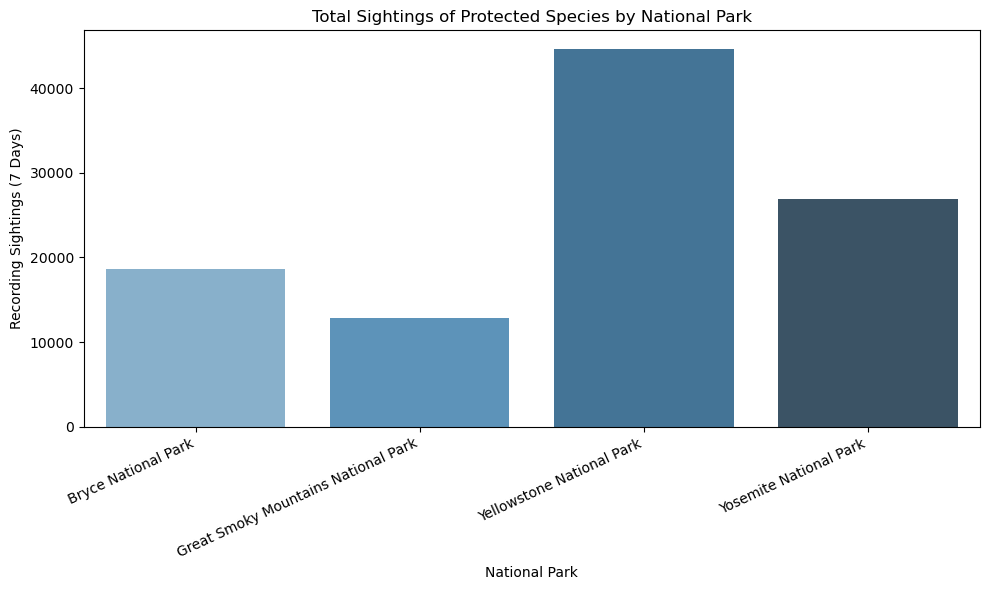

In [17]:
plt.figure(figsize=(10, 6))
sns.barplot(data=park_protected_counts, x='park_name', y='observations', hue='park_name', palette='Blues_d', legend=False)
plt.title('Total Sightings of Protected Species by National Park')
plt.xlabel('National Park')
plt.ylabel('Recording Sightings (7 Days)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()